# Week 3 - Linear Regression 3 (Subset Selection, PCR, and PLSR)
## Dataset: NOAA Storm Events

This week covers three ways to deal with a long list of possible features in linear regression. Forward and backward selection search for a smaller subset of the original features. Principal component regression (PCR) and partial least squares regression (PLSR) keep every feature but compress them into a few new components and regress on those instead.

The setup follows the Week 1 Storm Events notebook. The target is the log of property damage for events that reported some, and the split keeps whole storm episodes together. This time the candidate list is deliberately long, 47 features in all. It includes the Week 1 features plus casualty counts, crop damage, tornado EF rating, distance from the reference location, coordinates, time of day, and whether the event was reported for a forecast zone instead of a county. The question is which of these are worth keeping, and whether compressing them works better than choosing among them.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

warnings.filterwarnings('ignore', category=FutureWarning)

df = pd.read_csv('StormEvents_details-ftp_v1.0_d2017_c20260519.csv', low_memory=False)


def parse_damage(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip().upper()
    mult = {'K': 1e3, 'M': 1e6, 'B': 1e9}
    try:
        return float(val[:-1]) * mult[val[-1]] if val[-1] in mult else float(val)
    except ValueError:
        return np.nan


df['damageProperty'] = df['DAMAGE_PROPERTY'].apply(parse_damage)
df['damageCrops'] = df['DAMAGE_CROPS'].apply(parse_damage)
print('All 2017 events:', len(df), '| events with property damage above zero:', int((df['damageProperty'] > 0).sum()))

All 2017 events: 57041 | events with property damage above zero: 13439


### Candidate features

The 47 candidates cover the event itself (type, log duration, wind speed and its square, hail size, tornado path length, width, and EF rating), its consequences (log injuries, log deaths, and whether crop damage was reported), how and where it was recorded (report source, forecast zone vs. county, distance from the reference point, whether coordinates exist, latitude, longitude, and a night-start indicator), and the month. Categorical features are one-hot encoded with a baseline left out, which is thunderstorm wind for event type, Other for the report source, and January for the month.

Several candidates overlap almost completely, and the correlation table shows it. Zone-based events never have coordinates, so `zoneBased` and `hasCoordinates` have a correlation of -0.997. Hail size is 0 for everything except hail, so it tracks the hail indicator (0.92). Tornadoes are the events the NWS most often surveys in person, so the tornado indicator and the storm survey source correlate at 0.79. That kind of redundancy is exactly what all three methods in this notebook are meant to handle.

In [2]:
data = df[df['damageProperty'] > 0].copy()
begin = pd.to_datetime(data['BEGIN_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
end = pd.to_datetime(data['END_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
data['durationHours'] = ((end - begin).dt.total_seconds() / 3600).clip(lower=0)
data['month'] = begin.dt.month
data['hour'] = begin.dt.hour
data = data.dropna(subset=['month', 'durationHours']).reset_index(drop=True)
y = np.log10(data['damageProperty']).values
groups = data['EPISODE_ID'].values

X = pd.DataFrame(index=data.index)
X['logDuration'] = np.log10(data['durationHours'] + 0.1)
wind = data['EVENT_TYPE'].isin(['Thunderstorm Wind', 'High Wind', 'Strong Wind'])
X['windSpeed'] = np.where(wind, (data['MAGNITUDE'] - 50) / 10, 0.0)
X['windSpeedSquared'] = X['windSpeed'] ** 2
X['hailSize'] = np.where(data['EVENT_TYPE'] == 'Hail', data['MAGNITUDE'], 0.0)
tornado = data['EVENT_TYPE'] == 'Tornado'
log_len = np.log10(data['TOR_LENGTH'].fillna(0) + 0.1)
log_wid = np.log10(data['TOR_WIDTH'].fillna(0) + 1)
X['torLogLength'] = np.where(tornado, log_len - log_len[tornado].mean(), 0.0)
X['torLogWidth'] = np.where(tornado, log_wid - log_wid[tornado].mean(), 0.0)
ef = data['TOR_F_SCALE'].astype(str).str.extract(r'EF(\d)')[0].astype(float)
X['tornadoEF'] = np.where(tornado, ef.fillna(0), 0.0)
X['logInjuries'] = np.log10(data['INJURIES_DIRECT'] + data['INJURIES_INDIRECT'] + 1)
X['logDeaths'] = np.log10(data['DEATHS_DIRECT'] + data['DEATHS_INDIRECT'] + 1)
X['cropDamage'] = (data['damageCrops'] > 0).astype(float)
X['zoneBased'] = (data['CZ_TYPE'] == 'Z').astype(float)
X['beginRange'] = np.log10(data['BEGIN_RANGE'].fillna(0) + 1)
X['hasCoordinates'] = data['BEGIN_LAT'].notna().astype(float)
X['latitude'] = data['BEGIN_LAT'].fillna(data['BEGIN_LAT'].mean())
X['longitude'] = data['BEGIN_LON'].fillna(data['BEGIN_LON'].mean())
X['nightStart'] = ((data['hour'] >= 20) | (data['hour'] < 6)).astype(float)
top_types = data['EVENT_TYPE'].value_counts().head(10).index
event_type = data['EVENT_TYPE'].where(data['EVENT_TYPE'].isin(top_types), 'Other')
X = X.join(pd.get_dummies(event_type, prefix='type', dtype=float).drop(columns='type_Thunderstorm Wind'))
top_sources = data['SOURCE'].value_counts().head(10).index
source = data['SOURCE'].where(data['SOURCE'].isin(top_sources), 'Other')
X = X.join(pd.get_dummies(source, prefix='source', dtype=float).drop(columns='source_Other'))
X = X.join(pd.get_dummies(data['month'].astype(int), prefix='month', dtype=float).drop(columns='month_1'))
X.columns = [c.replace(' ', '') for c in X.columns]

print('Damaged events used:', len(data), '| candidate features:', X.shape[1])
print('Baselines: thunderstorm wind for event type, Other for report source, January for month')
print()
corr = X.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename('r').reset_index().assign(abs_r=lambda t: t['r'].abs()).sort_values('abs_r', ascending=False))
print('Most correlated pairs of candidate features:')
print(pairs.head(8)[['level_0', 'level_1', 'r']].round(3).to_string(index=False))

Damaged events used: 13439 | candidate features: 47
Baselines: thunderstorm wind for event type, Other for report source, January for month

Most correlated pairs of candidate features:
       level_0               level_1      r
     zoneBased        hasCoordinates -0.997
      hailSize             type_Hail  0.917
  type_Tornado source_NWSStormSurvey  0.793
     tornadoEF          type_Tornado  0.736
     tornadoEF source_NWSStormSurvey  0.629
hasCoordinates       type_StrongWind -0.626
     zoneBased       type_StrongWind  0.625
   logDuration        hasCoordinates -0.572


In [3]:
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]
g_train = groups[train_idx]
splits = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
print('Training events:', len(train_idx), '| test events:', len(test_idx),
      '| episodes in both:', len(set(g_train) & set(groups[test_idx])))


def cv_scores(cols):
    return cross_val_score(LinearRegression(), X_train[cols], y_train, cv=splits, scoring='r2')

Training events: 10140 | test events: 3299 | episodes in both: 0


### Forward selection and backward elimination

Forward selection starts with no features and, at each step, adds the one that raises grouped cross-validated R-squared the most. Backward elimination starts with all 47 and removes the one whose removal hurts the least (or helps the most). Both are greedy, so neither is guaranteed to find the best possible subset, but trying all $2^{47}$ subsets is out of the question. Every score here uses 5-fold cross-validation grouped by storm episode, so a feature only looks useful if it helps on storms the model has not seen.

In [4]:
t0 = time.time()
selected, remaining, forward = [], list(X.columns), []
while remaining:
    trial = {c: cv_scores(selected + [c]) for c in remaining}
    best = max(trial, key=lambda c: trial[c].mean())
    selected.append(best)
    remaining.remove(best)
    forward.append({'Step': len(selected), 'Added': best, 'CV R2': trial[best].mean(),
                    'CV SE': trial[best].std() / np.sqrt(5)})
forward = pd.DataFrame(forward)
print(f'Forward selection took {time.time() - t0:.0f} seconds')
print(forward[['Step', 'Added', 'CV R2']].head(20).round(4).to_string(index=False))
print('...')
print(forward[['Step', 'Added', 'CV R2']].tail(5).round(4).to_string(index=False))

Forward selection took 64 seconds
 Step                   Added  CV R2
    1             logDuration 0.1110
    2               windSpeed 0.2107
    3            type_Tornado 0.2944
    4               logDeaths 0.3193
    5                hailSize 0.3401
    6               type_Hail 0.3545
    7         type_StrongWind 0.3629
    8              type_Flood 0.3728
    9               tornadoEF 0.3796
   10 source_EmergencyManager 0.3869
   11                month_12 0.3929
   12                 month_9 0.3970
   13    source_911CallCenter 0.4012
   14   source_NWSStormSurvey 0.4046
   15                month_11 0.4075
   16   source_BroadcastMedia 0.4097
   17        type_WinterStorm 0.4111
   18          type_Lightning 0.4123
   19        windSpeedSquared 0.4132
   20              cropDamage 0.4141
...
 Step              Added  CV R2
   43            month_8 0.4062
   44 type_TropicalStorm 0.4037
   45         type_Other 0.4043
   46            month_3 0.4009
   47           month_10 

In [5]:
t0 = time.time()
current = list(X.columns)
backward = [{'Features left': len(current), 'Removed': '(none)', 'CV R2': cv_scores(current).mean()}]
while len(current) > 1:
    trial = {c: cv_scores([f for f in current if f != c]) for c in current}
    worst = max(trial, key=lambda c: trial[c].mean())
    current.remove(worst)
    backward.append({'Features left': len(current), 'Removed': worst, 'CV R2': trial[worst].mean()})
backward = pd.DataFrame(backward)
print(f'Backward elimination took {time.time() - t0:.0f} seconds')
print(backward.head(10).round(4).to_string(index=False))
kept_backward = {k: set(backward['Removed'].iloc[len(backward) - k + 1:]) | set(current) for k in range(1, X.shape[1] + 1)}
agree = [k for k in range(1, X.shape[1] + 1) if kept_backward[k] == set(forward['Added'].head(k))]
print()
print(f'Sizes where forward and backward pick exactly the same features: {len(agree)} of {X.shape[1]}')
best_back = backward.loc[backward['CV R2'].idxmax()]
print(f"Best backward model: {int(best_back['Features left'])} features, CV R2 {best_back['CV R2']:.4f}")

Backward elimination took 94 seconds
 Features left               Removed  CV R2
            47                (none) 0.3991
            46              month_10 0.4009
            45               month_3 0.4043
            44       type_FlashFlood 0.4060
            43             longitude 0.4074
            42               month_8 0.4087
            41      type_WinterStorm 0.4097
            40       type_StrongWind 0.4106
            39 source_TrainedSpotter 0.4112
            38              latitude 0.4118

Sizes where forward and backward pick exactly the same features: 5 of 47
Best backward model: 29 features, CV R2 0.4146


Best CV R2: 0.4160 with 25 features | one standard error: 0.0152
All 47 features: CV R2 0.3991
Smallest model within one standard error of the best: 13 features
Chosen features: ['logDuration', 'windSpeed', 'type_Tornado', 'logDeaths', 'hailSize', 'type_Hail', 'type_StrongWind', 'type_Flood', 'tornadoEF', 'source_EmergencyManager', 'month_12', 'month_9', 'source_911CallCenter']



scikit-learn's SequentialFeatureSelector picks the same set: True


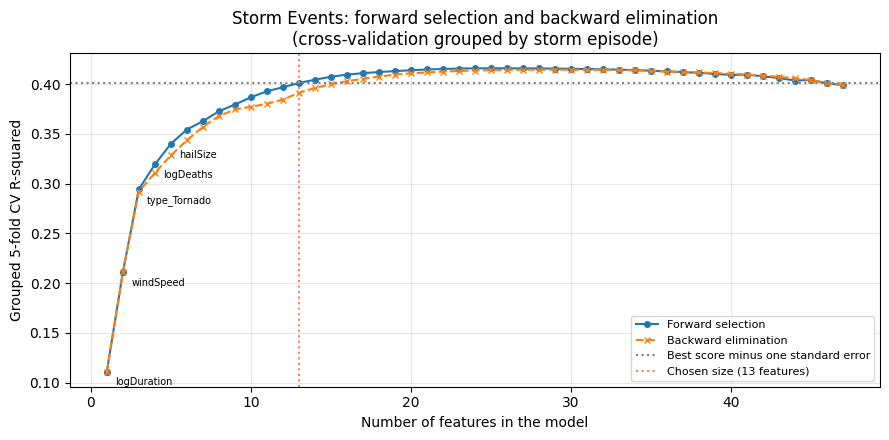

In [6]:
best_row = forward.loc[forward['CV R2'].idxmax()]
threshold = best_row['CV R2'] - best_row['CV SE']
k_best = int(best_row['Step'])
k_1se = int(forward.loc[forward['CV R2'] >= threshold, 'Step'].min())
print(f"Best CV R2: {best_row['CV R2']:.4f} with {k_best} features | one standard error: {best_row['CV SE']:.4f}")
print(f"All {X.shape[1]} features: CV R2 {forward['CV R2'].iloc[-1]:.4f}")
print(f'Smallest model within one standard error of the best: {k_1se} features')
chosen = list(forward['Added'].head(k_1se))
print('Chosen features:', chosen)

sfs = SequentialFeatureSelector(LinearRegression(), n_features_to_select=k_1se, direction='forward',
                                scoring='r2', cv=splits, n_jobs=-1).fit(X_train, y_train)
print()
print("scikit-learn's SequentialFeatureSelector picks the same set:",
      set(X.columns[sfs.get_support()]) == set(chosen))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(forward['Step'], forward['CV R2'], marker='o', markersize=4, label='Forward selection')
ax.plot(backward['Features left'], backward['CV R2'], marker='x', markersize=5, linestyle='--',
        label='Backward elimination')
ax.axhline(threshold, color='gray', linestyle=':', label='Best score minus one standard error')
ax.axvline(k_1se, color='coral', linestyle=':', label=f'Chosen size ({k_1se} features)')
for _, r in forward.head(5).iterrows():
    ax.annotate(r['Added'], (r['Step'], r['CV R2']), textcoords='offset points', xytext=(6, -10), fontsize=7)
ax.set_xlabel('Number of features in the model')
ax.set_ylabel('Grouped 5-fold CV R-squared')
ax.set_title('Storm Events: forward selection and backward elimination\n(cross-validation grouped by storm episode)')
ax.legend(fontsize=8, loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Forward selection picks the event's own characteristics first. Log duration alone gives a CV R-squared of 0.111, adding wind speed takes it to 0.211, and the tornado indicator, log deaths, and hail size bring it to 0.340 after five features. Report source and month enter later, between steps 10 and 16.

The most important result is the shape of the curve. Cross-validated R-squared peaks at 0.416 with 25 features and then falls to 0.399 when all 47 are used. In this dataset, more features make the model worse on new storms, because the extra columns (more month dummies, latitude, longitude, and rarely used sources) let the model fit patterns that belong to particular episodes. Subset selection here acts as a form of regularization. The one-standard-error rule picks the smallest model whose score is within one standard error (0.015) of the best, which gives 13 features. scikit-learn's `SequentialFeatureSelector` returns the same 13.

Forward and backward selection do not agree in this dataset. They pick exactly the same set at only 5 of the 47 possible sizes, and backward elimination's best model has 29 features with a CV R-squared of 0.415. The highly correlated pairs explain much of this. When two features carry almost the same information, which one survives depends on the order of the search. Backward elimination drops `type_FlashFlood` and `type_StrongWind` early, for example, because other features already cover most of what they say.

### Principal component regression and partial least squares

PCR standardizes the 47 features, finds the principal components (the directions of greatest variance in the features), and regresses log damage on the first few. PLSR also builds components, but it picks each one to have the highest covariance with the target, not the highest variance in the features. The next cell sweeps both from 1 to 47 components.

Component sweep took 51 seconds
 Components  PCR CV R2  PLSR CV R2
          1    -0.0001      0.3200
          2     0.0957      0.3525
          3     0.0982      0.3609
          4     0.2427      0.3666
          5     0.2663      0.3834
          6     0.2639      0.3942
          8     0.2763      0.3961
         10     0.2934      0.3988
         15     0.2981      0.3984
         20     0.3058      0.3982
         30     0.3068      0.3991
         40     0.3556      0.3991
         45     0.3989      0.3991
         46     0.3984      0.3991
         47     0.3991      0.3991

Components needed for 80% / 90% of the variance in X: 27 / 32
Components chosen by the one-standard-error rule: PCR 44, PLSR 6

Largest weights on the first PLS component: logDuration (+0.39), source_NWSStormSurvey (+0.30), tornadoEF (+0.28), windSpeed (+0.26), type_Tornado (+0.26), logDeaths (+0.26)
Largest loadings on the first principal component: hasCoordinates (+0.47), zoneBased (-0.47), logDuration

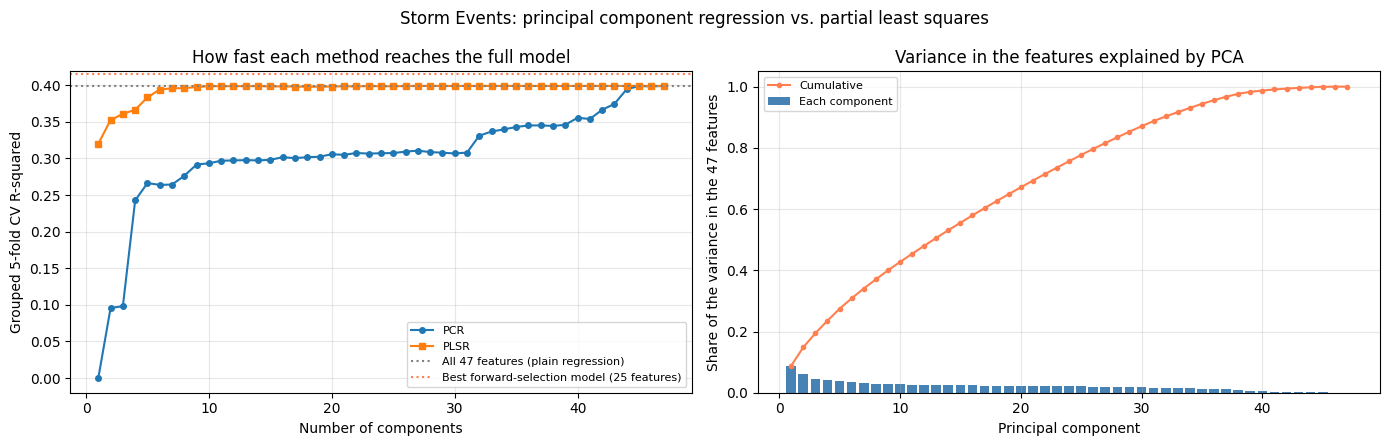

In [7]:
n_feat = X.shape[1]
pcr_rows = []
t0 = time.time()
for n in range(1, n_feat + 1):
    pcr = make_pipeline(StandardScaler(), PCA(n_components=n), LinearRegression())
    pls = PLSRegression(n_components=n, scale=True)
    s_pcr = cross_val_score(pcr, X_train, y_train, cv=splits, scoring='r2')
    s_pls = cross_val_score(pls, X_train, y_train, cv=splits, scoring='r2')
    pcr_rows.append({'Components': n, 'PCR CV R2': s_pcr.mean(), 'PCR SE': s_pcr.std() / np.sqrt(5),
                     'PLSR CV R2': s_pls.mean(), 'PLSR SE': s_pls.std() / np.sqrt(5)})
comps = pd.DataFrame(pcr_rows)
print(f'Component sweep took {time.time() - t0:.0f} seconds')
print(comps[comps['Components'].isin([1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30, 40, 45, 46, 47])]
      [['Components', 'PCR CV R2', 'PLSR CV R2']].round(4).to_string(index=False))

pca = PCA().fit(StandardScaler().fit_transform(X_train))
cum_var = np.cumsum(pca.explained_variance_ratio_)
print()
print('Components needed for 80% / 90% of the variance in X:',
      int(np.searchsorted(cum_var, 0.8) + 1), '/', int(np.searchsorted(cum_var, 0.9) + 1))


def pick_1se(score_col, se_col):
    best = comps.loc[comps[score_col].idxmax()]
    return int(comps.loc[comps[score_col] >= best[score_col] - best[se_col], 'Components'].min())


k_pcr, k_pls = pick_1se('PCR CV R2', 'PCR SE'), pick_1se('PLSR CV R2', 'PLSR SE')
print(f'Components chosen by the one-standard-error rule: PCR {k_pcr}, PLSR {k_pls}')

pls1 = PLSRegression(n_components=1, scale=True).fit(X_train, y_train)
w = pd.Series(pls1.x_weights_[:, 0], index=X.columns)
print()
print('Largest weights on the first PLS component:',
      ', '.join(f'{f} ({w[f]:+.2f})' for f in w.abs().sort_values(ascending=False).head(6).index))
print('Largest loadings on the first principal component:',
      ', '.join(f'{f} ({pca.components_[0][list(X.columns).index(f)]:+.2f})'
                for f in pd.Series(np.abs(pca.components_[0]), index=X.columns).sort_values(ascending=False).head(6).index))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(comps['Components'], comps['PCR CV R2'], marker='o', markersize=4, label='PCR')
axes[0].plot(comps['Components'], comps['PLSR CV R2'], marker='s', markersize=4, label='PLSR')
axes[0].axhline(forward['CV R2'].iloc[-1], color='gray', linestyle=':', label=f'All {n_feat} features (plain regression)')
axes[0].axhline(best_row['CV R2'], color='coral', linestyle=':', label=f'Best forward-selection model ({k_best} features)')
axes[0].set_xlabel('Number of components')
axes[0].set_ylabel('Grouped 5-fold CV R-squared')
axes[0].set_title('How fast each method reaches the full model')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
axes[1].bar(range(1, n_feat + 1), pca.explained_variance_ratio_, color='steelblue', label='Each component')
axes[1].plot(range(1, n_feat + 1), cum_var, color='coral', marker='o', markersize=3, label='Cumulative')
axes[1].set_xlabel('Principal component')
axes[1].set_ylabel(f'Share of the variance in the {n_feat} features')
axes[1].set_title('Variance in the features explained by PCA')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
fig.suptitle('Storm Events: principal component regression vs. partial least squares')
plt.tight_layout()
plt.show()

### Final evaluation on held-out storm episodes

Test events (unseen episodes): 3299
                                       Model  Features used  Train R2  Test R2  Test RMSE (log10)
          All 47 features (plain regression)             47    0.4363   0.4375             0.7674
    Forward selection, best CV (25 features)             25    0.4289   0.4563             0.7546
Forward selection, one-SE rule (13 features)             13    0.4090   0.4310             0.7719
                          PCR, 44 components             47    0.4349   0.4398             0.7659
                          PLSR, 6 components             47    0.4319   0.4426             0.7640


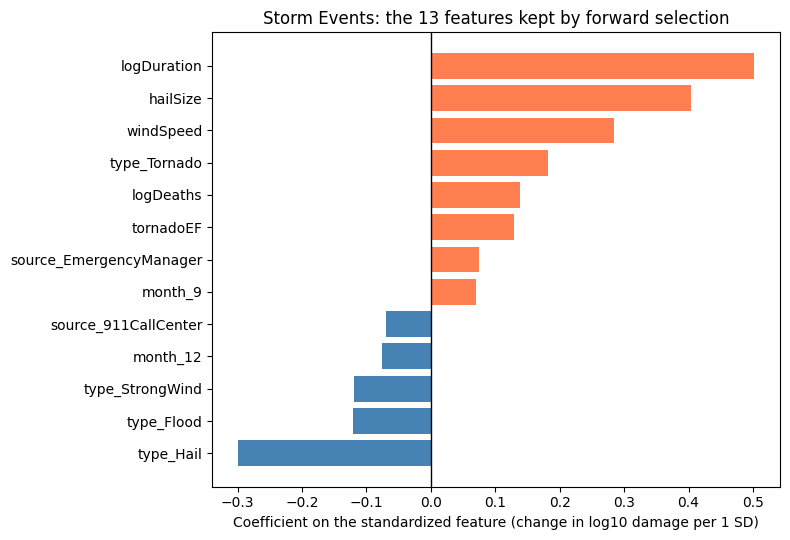

In [8]:
models = {
    f'All {n_feat} features (plain regression)': (list(X.columns), LinearRegression()),
    f'Forward selection, best CV ({k_best} features)': (list(forward['Added'].head(k_best)), LinearRegression()),
    f'Forward selection, one-SE rule ({k_1se} features)': (chosen, LinearRegression()),
    f'PCR, {k_pcr} components': (list(X.columns), make_pipeline(StandardScaler(), PCA(k_pcr), LinearRegression())),
    f'PLSR, {k_pls} components': (list(X.columns), PLSRegression(k_pls, scale=True)),
}
rows = []
for name, (cols, model) in models.items():
    model.fit(X_train[cols], y_train)
    pred_tr = np.ravel(model.predict(X_train[cols]))
    pred_te = np.ravel(model.predict(X_test[cols]))
    rows.append({'Model': name, 'Features used': len(cols), 'Train R2': r2_score(y_train, pred_tr),
                 'Test R2': r2_score(y_test, pred_te), 'Test RMSE (log10)': mean_squared_error(y_test, pred_te) ** 0.5})
final = pd.DataFrame(rows)
print('Test events (unseen episodes):', len(test_idx))
print(final.round(4).to_string(index=False))

sel_model = LinearRegression().fit(StandardScaler().fit_transform(X_train[chosen]), y_train)
coef = pd.Series(sel_model.coef_, index=chosen).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(coef.index, coef.values, color=np.where(coef.values > 0, 'coral', 'steelblue'))
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Coefficient on the standardized feature (change in log10 damage per 1 SD)')
ax.set_title(f'Storm Events: the {k_1se} features kept by forward selection')
plt.tight_layout()
plt.show()

The two methods behave very differently. PLSR's first component alone reaches a CV R-squared of 0.320, and with 6 components it is at 0.394, close to the full model's 0.399. PCR's first component explains nothing (CV R-squared -0.0001), five components reach only 0.266, and it needs 44 components before it catches up, which is almost no compression at all.

The loadings show why. The first principal component is mostly `hasCoordinates` and `zoneBased`, the near-duplicate pair, plus the strong wind type and distance from the reference point. That component captures the biggest split in how events are recorded (zone events vs. point events), which has little to do with how much damage they cause. PCA has no way to know that, because it never looks at the target. The first PLS component instead weights log duration, the storm survey source, tornado EF rating, wind speed, the tornado indicator, and log deaths, which are the same features forward selection picked early.

On the 3,299 test events from unseen episodes, forward selection with 25 features scores best (test R-squared 0.456), ahead of all 47 features (0.438), PLSR with 6 components (0.443), and PCR with 44 components (0.440). The one-standard-error model with 13 features scores 0.431, giving up about 0.025 in exchange for using roughly half as many features. All the test scores are higher than the matching cross-validated scores, which suggests the test episodes happen to be a little easier to predict, so the comparison between models matters more than the absolute values.

## Discussion

### Overfitting

All three methods in this notebook are tools against overfitting, and they work in different ways. Subset selection removes features, and in this dataset that clearly helped. Grouped CV R-squared fell from 0.416 at 25 features to 0.399 at 47, and the test set agreed (0.456 against 0.438). PCR and PLSR keep every feature but cap how many directions the model can use. That keeps the coefficients stable when features are correlated, but it cannot drop a noisy feature, so neither method beat the full model by much.

Two things kept the selection itself honest. Every step used cross-validation grouped by storm episode, and the final comparison used test episodes that played no part in any choice. The CV score of the selected model is still slightly optimistic, because the same folds that chose the features also scored them. That is the reason for checking it once more on the test set.

### Metrics and hyperparameter tuning

R-squared on log damage was the main metric, with RMSE in log10 units on the test set. The tuned settings were the number of features for subset selection and the number of components for PCR and PLSR. In both cases the one-standard-error rule picked the final value, choosing the simplest model whose CV score is within one standard error of the best. A smaller number means a simpler model that is easier to explain and less likely to fit noise, and the rule makes that trade explicit. It picked 13 features, 6 PLSR components, and 44 PCR components.

### Expected or unexpected

I expected PLSR to need fewer components than PCR, since that is the whole point of PLSR, but not by this much (6 against 44). I also expected forward and backward selection to land on similar sets, as they mostly do for NFIP (the same set at 28 of 31 sizes). Here they disagree at almost every size, because so many candidates are near-duplicates of each other.

The most useful surprise was that the full model is worse than a selected subset on unseen storms. With 10,140 training events and 47 features, I did not expect overfitting to show up at all, but grouping the folds by episode makes each extra feature prove itself on new storms, and the last 20 or so do not.

Log deaths entering at step 4 was also unexpected, since casualties explained so little in Module B. Within a model that already knows the event type and its intensity, deaths separate the truly destructive events from the rest. Like the report source, though, deaths are a consequence of the event, so they belong in a model that describes damage, not one meant to predict it ahead of time.

### How EDA helped

The correlation check before modeling was the most useful EDA step this week. It flagged the near-duplicate pairs (zone vs. coordinates, hail size vs. hail type, tornado vs. storm survey) that later explained why forward and backward selection disagree and why PCR's first component is useless. The Module B finding that damage is right-skewed is why the target is logged, and the Week 1 finding that `MAGNITUDE` mixes knots and inches is why wind speed and hail size enter as separate, type-specific columns.

### External sources

- scikit-learn User Guide, "Sequential Feature Selection": https://scikit-learn.org/stable/modules/feature_selection.html#sequential-feature-selection
- scikit-learn example, "Principal Component Regression vs Partial Least Squares Regression," which shows the same pattern of PCR missing a direction that PLS finds: https://scikit-learn.org/stable/auto_examples/cross_decomposition/plot_pcr_vs_pls.html
- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, Chapter 6 ("Linear Model Selection and Regularization"), sections on subset selection, the one-standard-error rule, and dimension reduction methods.

### Conclusions

Out of 47 candidate features, about 25 are worth keeping for predicting the size of storm damage on unseen storms, and keeping them gives the best test R-squared in this notebook (0.456), above the full model (0.438) and both compression methods. The features that matter most describe the event itself (duration, wind speed, hail size, tornado rating) and a few describe how it was recorded or what it caused (report source, deaths). PLSR matched the full model with only 6 components, while PCR needed 44, because the main variation among these features is about record-keeping, not damage.

For the Capstone, this supports keeping the Storm Events model small and choosing its features with grouped validation, and it shows that PCA-style compression should not be the default for this data. It also sharpens the line between features that describe storm conditions and features that describe the aftermath, which matters if the goal is to explain damage before it happens.